# 02 · Physical-state detection
Compares A41-A44 for detecting physical states from current for one machine (`MACHINE`). The number of states comes from each machine's histogram (`C.STATES`): machine 4 has **Off, Panel, Started, Cutting**; machine 3 has **Off, Panel, Operating** (no separate started level), scores them with G1-G6, then builds hours per state and T_op. Related to H45-H47, R36/R37/R42. Run once with `MACHINE = 4`, then again with `MACHINE = 3`; models are always fitted per machine because current levels differ (H45). CSV outputs use Indonesian labels for the report.

In [1]:
import sys, time
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "config.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.mixture import GaussianMixture
from sklearn.metrics import accuracy_score, precision_score, recall_score, cohen_kappa_score
import config as C
from src import detection as D

MACHINE = 4                                  # 4, then 3
K = C.STATES[MACHINE]                        # number of physical states (from the histogram)
STATE, LABEL = D.names(K)
SPLIT = pd.Timestamp("2026-08-01")           # before SPLIT: training period (RF, cross-time test)
SAMPLE_DAYS = ["2026-09-08", "2026-10-14"]   # local date

ID = {"A41 Threshold": "A41 Ambang", "accuracy": "akurasi", "precision": "presisi", "flickers_per_day": "kedipan_per_hari",
      "switches_per_day": "perpindahan_per_hari", "cutting_hours": "jam_memotong", "seconds_per_day": "detik_per_hari",
      "score": "skor", "agreement_pct": "kesesuaian_pct", "hold": "tunda", "month": "bulan", "state": "kondisi",
      "G1 label-free": "G1 tanpa label", "G2 accuracy": "G2 akurasi", "G3 manual params": "G3 param manual",
      "G4 s/day": "G4 detik/hari", "G5 flickers/day": "G5 kedipan/hari", "G6 explainability": "G6 keterjelasan",
      "T_op (started+cutting)": "T_op (start+potong)", "T_op (cutting)": "T_op (potong)",
      "T_op (operating)": "T_op (beroperasi)", **{STATE[k]: LABEL[k] for k in STATE}}
save = lambda t, name, **kw: t.rename(index=ID, columns=ID).rename_axis(index=ID.get(t.index.name, t.index.name) or "metode") \
                              .to_csv(C.TAB / f"m{MACHINE}_{name}.csv", **kw)

df = pd.read_parquet(C.SILVER / "timeline.parquet", filters=[("machine", "==", MACHINE)]).reset_index(drop=True)
df["missing"] = ~df.has_data | df.I.isna()
df["day"] = df.t_local.dt.strftime("%Y-%m-%d")
df["month"] = df.t_local.dt.strftime("%Y-%m")
df["excluded"] = df.day.isin(C.TEST_DAYS + C.ANOMALY_DAYS)
valid = (~df.missing & ~df.meter_off).to_numpy()
x = D.log_current(df.I[valid], C.NOISE_A)
n_days = df.day[~df.missing].nunique()
print(f"Patch {C.PATCH}, machine {MACHINE}: {len(df):,} slots, {n_days} days with data, {valid.mean():.1%} valid slots (data present, meter on)")

Patch patch1, machine 4: 2,183,058 slots, 127 days with data, 99.6% valid slots (data present, meter on)


## 0 · Current over one day
Raw three-phase current (log scale) on one sample day, before any method: the current jumps between a few levels and stays at each level for a while.

In [ ]:
day = SAMPLE_DAYS[0]                                 # same day for both machines
m = (df.day == day).to_numpy()
plt.figure(figsize=(12, 3))
plt.semilogy(df.t_local[m], df.I[m] + D.EPS, lw=.6)
plt.ylabel("Current I (A), log scale"); plt.xlabel("Local time (WIB)")
plt.title(f"Machine {MACHINE}, {day}: three-phase current")
plt.tight_layout(); plt.savefig(C.FIG / f"m{MACHINE}_current_{day}.png"); plt.show()

Plain histogram of the 5-s current over the whole period, before any method: no noise floor, no valleys, no smoothing. 0 A is shown at 0.001 A so it fits on the log axis. Each peak is a current level that occurs often.

In [ ]:
I_raw = df.I[valid].to_numpy()
plt.figure(figsize=(9, 3))
plt.hist(np.clip(I_raw, 1e-3, None), bins=np.logspace(-3, 2.7, 200), log=True)   # 0 A shown at 0.001 A
plt.xscale("log"); plt.xlabel("Current I (A), log scale"); plt.ylabel("Number of 5-s samples (log scale)")
plt.title(f"Machine {MACHINE}: distribution of current, whole period")
plt.tight_layout(); plt.savefig(C.FIG / f"m{MACHINE}_current_hist.png"); plt.show()

## 1 · Log current and histogram valleys
$x = \log_{10}(I + 0.01)$: levels 0 / 0.1-1 / 2-6 / ~100 A become almost evenly spaced and each is close to normal (basis of GMM/HMM). One peak per physical state should appear (`K` from `C.STATES`); machine 3 has no separate started peak.

Peaks (A): [  0.      0.283   4.319 104.525] | Valleys (A): [4.0000e-03 5.8000e-01 4.9333e+01]
States used: 4 (C.STATES)


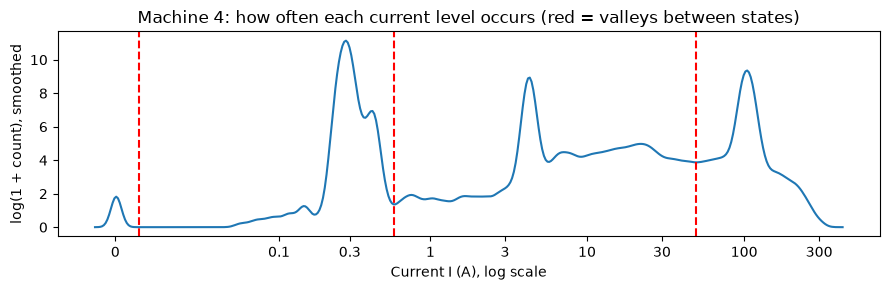

In [3]:
valleys, c, hs, peaks = D.find_valleys(x, n=K)
print("Peaks (A):", D.to_amps(peaks).round(3), "| Valleys (A):", D.to_amps(valleys).round(3))
print(f"States used: {K} (C.STATES)")
if len(peaks) < K: print(f"WARNING: fewer than {K} peaks, check the histogram")
amps = [0, 0.1, 0.3, 1, 3, 10, 30, 100, 300]
plt.figure(figsize=(9, 3)); plt.plot(c, hs)
for v in valleys: plt.axvline(v, ls="--", c="r")
plt.xticks(D.log_current(amps), amps)
plt.xlabel("Current I (A), log scale"); plt.ylabel("log(1 + count), smoothed")
plt.title(f"Machine {MACHINE}: how often each current level occurs (red = valleys between states)"); plt.tight_layout()
plt.savefig(C.FIG / f"m{MACHINE}_histogram.png"); plt.show()

## 2 · HMM as a Bayesian network
Hidden machine state $x_k$ evolves as a Markov chain ($x_{k-1} \to x_k$); current $y_k$ and operator log $s_k$ are both noisy observations of it (shaded = observed).

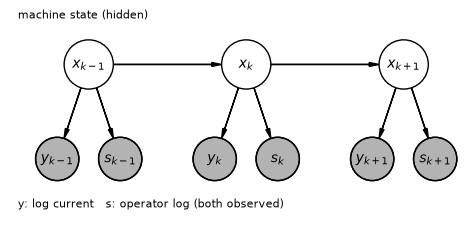

In [11]:
import daft

pgm = daft.PGM()
for i, k in enumerate(["k-1", "k", "k+1"]):
    pgm.add_node(f"x{i}", rf"$x_{{{k}}}$", 2 * i + 1, 2.2, scale=1.25)
    pgm.add_node(f"y{i}", rf"$y_{{{k}}}$", 2 * i + 0.6, 1, scale=1.1, observed=True)
    pgm.add_node(f"s{i}", rf"$s_{{{k}}}$", 2 * i + 1.4, 1, scale=1.1, observed=True)
    pgm.add_edge(f"x{i}", f"y{i}"); pgm.add_edge(f"x{i}", f"s{i}")
    if i: pgm.add_edge(f"x{i-1}", f"x{i}")
pgm.add_text(0.1, 2.75, "machine state (hidden)", fontsize=8)
pgm.add_text(0.1, 0.35, "y: log current   s: operator log (both observed)", fontsize=8)
pgm.render()
pgm.savefig(C.FIG / "hmm_bn.png", dpi=200)

## 3 · Four methods
- **A41 Threshold:** up when $x > L_k + \delta$, down when $x < L_{k-1} - \delta$, must hold for `hold` samples (Schmitt trigger + debounce).
- **A42 GMM:** $p(x) = \sum_j \pi_j \mathcal N(x \mid \mu_j, \sigma_j^2)$, $k$ physical states from `C.STATES`; BIC $= -2\ln\hat L + p\ln n$ as a check.
- **A43 HMM:** GMM + dynamics $P(z_t = j \mid z_{t-1} = i) = a_{ij}$; Viterbi acts like an observer (Ogata) that rejects short spikes. Basis of H47.
- **A44 RF:** supervised with RUNNING labels (trained before 1 Aug), binary only.

In [4]:
T, S = {}, {}
t0 = time.perf_counter(); k_thr = D.threshold(x, valleys); T["A41 Threshold"] = time.perf_counter() - t0

bic = {k: GaussianMixture(k, random_state=0).fit(x[::7, None]).bic(x[::7, None]) for k in range(2, 8)}
t0 = time.perf_counter(); k_gmm, g = D.gmm(x, k=K); T["A42 GMM"] = time.perf_counter() - t0

lengths = D.segments(valid)
t0 = time.perf_counter(); k_hmm, h = D.hmm(x, lengths, g); T["A43 HMM"] = time.perf_counter() - t0

sub = df[valid]
F = sub[["I", "va", "vx", "vy", "vz", "freq"]].fillna(0).to_numpy()
y = (sub.status == "RUNNING").to_numpy()
train = ((sub.t < SPLIT) & sub.status.notna() & ~sub.excluded).to_numpy()
t0 = time.perf_counter()
rf = RandomForestClassifier(100, min_samples_leaf=5, max_samples=min(200_000, train.sum()), n_jobs=-1, random_state=0)
k_rf = np.where(rf.fit(F[train], y[train]).predict(F), 3, 0); T["A44 RF"] = time.perf_counter() - t0

def to_grid(k):
    s = np.full(len(df), -1, np.int8); s[df.meter_off.to_numpy()] = 0; s[valid] = k; return s
S = {m: to_grid(k) for m, k in zip(T, [k_thr, k_gmm, k_hmm, k_rf])}
print("Lowest BIC at k =", min(bic, key=bic.get))
print("GMM state means (A):", D.to_amps(np.sort(g.means_.ravel())).round(3))
print(f"HMM converged: {h.monitor_.converged} ({h.monitor_.iter} iterations)")
print({m: f"{t:.1f} s" for m, t in T.items()})

Lowest BIC at k = 7
GMM state means (A): [  0.      0.287   4.54  103.86 ]
HMM converged: True (9 iterations)
{'A41 Threshold': '1.5 s', 'A42 GMM': '26.1 s', 'A43 HMM': '54.8 s', 'A44 RF': '18.9 s'}


## 4 · HMM parameters λ = (A, B, π)
- **A**: $a_{ij} = n_{ij}/n_i$, share of 5-s steps starting in state $i$ that end in state $j$. Baum-Welch learns it from current alone using expected counts (Rabiner & Juang 1986, Box 3); counting the decoded states gives the same idea with hard counts, as a check. $\bar d_i = 1/(1-a_{ii})$ steps is the mean time spent in state $i$.
- **B**: Gaussian $b_j(o) = \mathcal N(o; \mu_j, \sigma_j^2)$ on log current; plotted over the histogram, each curve should sit on one peak.
- **π**: initial state probabilities.

In [ ]:
names = [STATE[c] for c in D.CODES[K]]
o = np.argsort(h.means_.ravel())                                   # hidden states sorted by current level
mu, var = h.means_.ravel()[o], h.covars_.ravel()[o]
A_bw = pd.DataFrame(h.transmat_[np.ix_(o, o)], index=names, columns=names)
s = S["A43 HMM"]; ok = (s[:-1] >= 0) & (s[1:] >= 0)                # count only steps with data on both ends
A_cnt = pd.crosstab(pd.Series(s[:-1][ok]).map(STATE), pd.Series(s[1:][ok]).map(STATE),
                    normalize="index").reindex(index=names, columns=names, fill_value=0)
par = pd.DataFrame({"a_ii": np.diag(A_bw), "mean_stay_s": 5 / (1 - np.diag(A_bw)), "pi": h.startprob_[o],
                    "mean_A": D.to_amps(mu), "sigma_log": np.sqrt(var), "share": [np.mean(k_hmm == c) for c in D.CODES[K]]}, index=names)
print("Baum-Welch:"); display(A_bw.round(5)); print("Counted from decoded states:"); display(A_cnt.round(5)); display(par.round(4))

grid = np.linspace(x.min() - .1, x.max() + .1, 800)
plt.figure(figsize=(9, 3))
plt.hist(x, bins=200, density=True, color="lightgrey", label="log current (data)")
for n, m_, v_, w_ in zip(names, mu, var, par.share):
    plt.plot(grid, w_ * np.exp(-(grid - m_) ** 2 / (2 * v_)) / np.sqrt(2 * np.pi * v_), lw=1.4, label=f"{n}: μ ≈ {D.to_amps(m_):.2f} A")
plt.yscale("log"); plt.ylim(1e-3, 1e2); plt.xticks(D.log_current(amps), amps)
plt.xlabel("Current I (A), log scale"); plt.ylabel("Density (log scale)"); plt.legend(fontsize=8)
plt.title(f"Machine {MACHINE}: HMM observation model B over the current histogram"); plt.tight_layout()
plt.savefig(C.FIG / f"m{MACHINE}_hmm_emission.png"); plt.show()

A_bw.rename(index=ID, columns=ID).to_csv(C.TAB / f"m{MACHINE}_transisi.csv")
par.rename(index=ID, columns={"a_ii": "peluang_tetap", "mean_stay_s": "rata_bertahan_detik", "pi": "peluang_awal",
                              "mean_A": "rata_arus_A", "sigma_log": "simpangan_log10", "share": "porsi_waktu"}) \
   .to_csv(C.TAB / f"m{MACHINE}_parameter_hmm.csv")

## 5 · Evaluation
Test set: from 1 Aug, status present, test/anomaly days excluded. *Cutting* is compared with *RUNNING*. RUNNING itself is imperfect (P30), so this is **agreement with the label**, not absolute truth.
**Flicker** = Cutting run ≤ 10 s; each one can become a false start-stop event that lowers MTBF.

In [5]:
test = ((df.t >= SPLIT) & ~df.missing & df.status.notna() & ~df.excluded).to_numpy()
yt = (df.status == "RUNNING").to_numpy()
ev = pd.DataFrame({m: {
        "accuracy": accuracy_score(yt[test], s[test] == 3), "precision": precision_score(yt[test], s[test] == 3),
        "recall": recall_score(yt[test], s[test] == 3), "kappa": cohen_kappa_score(yt[test], s[test] == 3),
        "flickers_per_day": D.flickers(s) / n_days, "switches_per_day": np.sum(s[1:] != s[:-1]) / n_days,
        "cutting_hours": np.sum(s == 3) * 5 / 3600, "seconds_per_day": T[m] / n_days}
      for m, s in S.items()}).T
display(ev.round(4))

ok = ~df.missing & df.status.notna() & ~df.excluded
monthly = pd.DataFrame({m: pd.Series((s == 3) == yt)[ok].groupby(df.month[ok]).mean() for m, s in S.items()})
display((monthly * 100).round(2))   # RF in Jun-Jul is scored on its own training data (optimistic)
save(ev, "evaluasi"); save(monthly, "kecocokan_bulanan")

,accuracy,precision,recall,kappa,flickers_per_day,switches_per_day,cutting_hours,seconds_per_day
A41 Threshold,0.9903,0.9931,0.8996,0.9387,0.5591,25.4252,222.3708,0.0118
A42 GMM,0.9908,0.9958,0.9022,0.9417,1.9764,28.9370,222.4431,0.2053
A43 HMM,0.9908,0.9960,0.9021,0.9417,1.6457,28.2598,222.3403,0.4312
A44 RF,0.9822,0.8974,0.9073,0.8925,33.4961,111.5197,248.1472,0.1486


,A41 Threshold,A42 GMM,A43 HMM,A44 RF
month,,,,
2026-06,96.22,96.26,96.25,97.81
2026-07,98.95,99.03,99.03,99.07
2026-08,98.79,98.84,98.84,98.59
2026-09,98.79,98.85,98.85,96.92
2026-10,99.83,99.86,99.86,99.73


## 6 · G1-G6 score
$s_i = \mathrm{clip}\big((v_i - v_{und})/(v_{des} - v_{und}), 0, 1\big)$, score $= \sum w_i s_i$, with the same limits and weights as the Proyek sheet. Then 10,000 random weight sets test whether the winner depends on the weights.

In [6]:
CRIT = pd.DataFrame({"G1 label-free": (0, 1, .15), "G2 accuracy": (.971, 1, .35), "G3 manual params": (3, 0, .10),
                  "G4 s/day": (5, 0, .05), "G5 flickers/day": (20, 0, .20), "G6 explainability": (0, 1, .15)},
                 index=["und", "des", "w"]).T
V = pd.DataFrame({"G1 label-free": [1, 1, 1, 0], "G2 accuracy": ev.accuracy, "G3 manual params": [3, 0, 0, 0],
                  "G4 s/day": ev.seconds_per_day, "G5 flickers/day": ev.flickers_per_day,
                  "G6 explainability": [1, .5, .5, 0]}, index=ev.index)
N = ((V - CRIT.und) / (CRIT.des - CRIT.und)).clip(0, 1)
score = (N @ CRIT.w).sort_values(ascending=False).rename("score")
wins = pd.Series([(N @ w).idxmax() for w in np.random.default_rng(0).dirichlet(np.ones(6), 10_000)]).value_counts(normalize=True)
display(pd.concat([V, score, (wins * 100).rename("pct_wins")], axis=1).sort_values("score", ascending=False).round(3))
save(pd.concat([V, N.rename(columns=ID).add_suffix(" (norm)"), score], axis=1), "skor")

,G1 label-free,G2 accuracy,G3 manual params,G4 s/day,G5 flickers/day,G6 explainability,score,pct_wins
A43 HMM,1,0.991,0,0.431,1.646,0.5,0.793,15.63
A42 GMM,1,0.991,0,0.205,1.976,0.5,0.792,44.92
A41 Threshold,1,0.990,3,0.012,0.559,1.0,0.777,39.45
A44 RF,0,0.982,0,0.149,33.496,0.0,0.283,NaN


## 7 · Robustness tests
- **Cross-time:** models fitted only on data before 1 Aug are applied after it and compared with full-data models. High agreement means the model can be reused for later patches.
- **A41 sensitivity:** δ and hold are varied.

In [7]:
early = (df.t[valid] < SPLIT).to_numpy(); late = ~early
len_early = D.segments(valid & (df.t < SPLIT).to_numpy())
k_thr2 = D.threshold(x, D.find_valleys(x[early], n=K)[0])
k_gmm2, g2 = D.gmm(x, k=K, x_fit=x[early])
k_hmm2, _ = D.hmm(x, lengths, g2, x_fit=x[early], len_fit=len_early)
cross = pd.Series({"A41 Threshold": np.mean(k_thr2[late] == k_thr[late]), "A42 GMM": np.mean(k_gmm2[late] == k_gmm[late]),
                   "A43 HMM": np.mean(k_hmm2[late] == k_hmm[late])}, name="agreement_pct") * 100
display(cross.round(3))

sens = pd.DataFrame([{"delta": d, "hold": n, "accuracy": accuracy_score(yt[test], to_grid(kk)[test] == 3),
                      "flickers_per_day": D.flickers(to_grid(kk)) / n_days}
                     for d in (.02, .05, .10) for n in (1, 2, 3, 6) for kk in [D.threshold(x, valleys, d, n)]])
display(sens.round(4))
save(cross.to_frame(), "lintas_waktu"); save(sens, "sensitivitas_ambang", index=False)

A41 Threshold    99.698
A42 GMM          99.675
A43 HMM          99.673
Name: agreement_pct, dtype: float64

,delta,hold,accuracy,flickers_per_day
0,0.02,1,0.9908,1.9685
1,0.02,2,0.9904,0.6142
2,0.02,3,0.9895,0.0866
3,0.02,6,0.9868,0.0709
4,0.05,1,0.9908,1.7953
5,0.05,2,0.9903,0.5591
6,0.05,3,0.9894,0.0866
7,0.05,6,0.9867,0.0709
8,0.10,1,0.9908,1.5906
9,0.10,2,0.9902,0.5276


## 8 · Reconstruction
The best-scoring label-free method is used for now; the final choice comes after machine 3. T_op is given two ways for Q137/R42: **Started + Cutting** and **Cutting only**.

In [8]:
CHOSEN = score.drop("A44 RF").idxmax()          # override if needed, e.g. CHOSEN = "A43 HMM"
s = S[CHOSEN]; state = pd.Series(s).map(STATE).rename("state")
hours = pd.crosstab(df.month, state) * 5 / 3600
hours["T_op (started+cutting)"] = hours.get(STATE[2], 0) + hours.get(STATE[3], 0)   # machine 3: operating only
hours[f"T_op ({STATE[3].lower()})"] = hours.get(STATE[3], 0)
hours.loc["Total"] = hours.sum()
print("Method:", CHOSEN); display(hours.round(1))

m = ~df.missing & df.status.notna()
cross_status = pd.crosstab(df.status[m], state[m]) * 5 / 3600
display(cross_status.round(1)); display((cross_status.div(cross_status.sum(axis=1), axis=0) * 100).round(1))
save(hours, "jam_kondisi"); save(cross_status, "kondisi_vs_status")

Method: A43 HMM


state,Cutting,Off,Panel,Started,Unknown,T_op (started+cutting),T_op (cutting)
month,,,,,,,
2026-06,20.4,126.8,199.0,27.6,3.3,48.0,20.4
2026-07,46.3,546.0,82.5,69.2,0.0,115.6,46.3
2026-08,75.1,425.0,174.8,61.4,7.6,136.6,75.1
2026-09,62.3,52.6,549.1,53.7,2.2,116.0,62.3
2026-10,18.2,87.8,325.0,15.5,0.5,33.7,18.2
Total,222.3,1238.2,1330.4,227.5,13.6,449.8,222.3


state,Cutting,Off,Panel,Started
status,,,,
BIG_BREAK,0.0,0.0,30.9,5.9
BREAKDOWN,0.0,0.1,0.3,0.0
IDLE,0.9,104.2,343.7,168.3
IDLE_INSPECT_DIM,0.0,0.0,2.5,4.6
IDLE_INSPECT_NDT,0.0,0.0,0.4,0.0
IDLE_REPAIR_MECHANICAL,0.0,0.0,0.6,0.4
IDLE_REPAIR_WELDING,0.0,0.0,3.9,3.0
MAINTENANCE,0.0,0.0,0.2,0.1
POWER_OFF,0.0,1131.1,0.0,0.0


state,Cutting,Off,Panel,Started
status,,,,
BIG_BREAK,0.0,0.0,83.9,16.1
BREAKDOWN,0.0,13.3,80.2,6.5
IDLE,0.1,16.9,55.7,27.3
IDLE_INSPECT_DIM,0.1,0.1,34.8,64.9
IDLE_INSPECT_NDT,0.0,1.4,97.8,0.7
IDLE_REPAIR_MECHANICAL,0.0,0.7,58.6,40.7
IDLE_REPAIR_WELDING,0.0,0.0,56.4,43.6
MAINTENANCE,0.4,7.2,76.2,16.2
POWER_OFF,0.0,100.0,0.0,0.0


Visual check: do state changes line up with current changes, and where do the methods disagree?

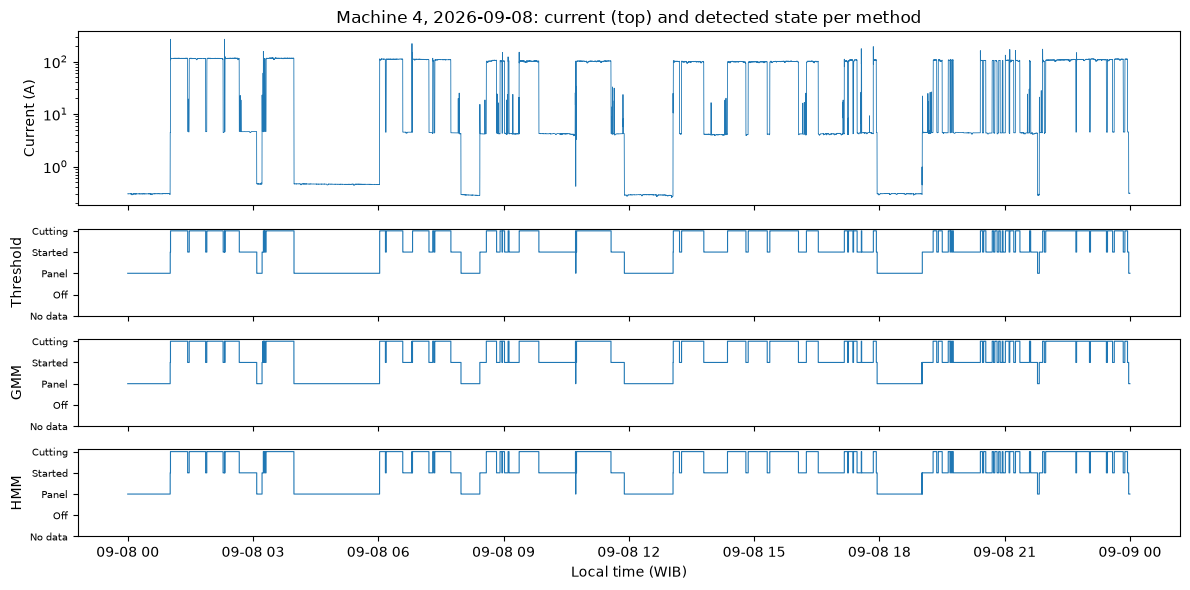

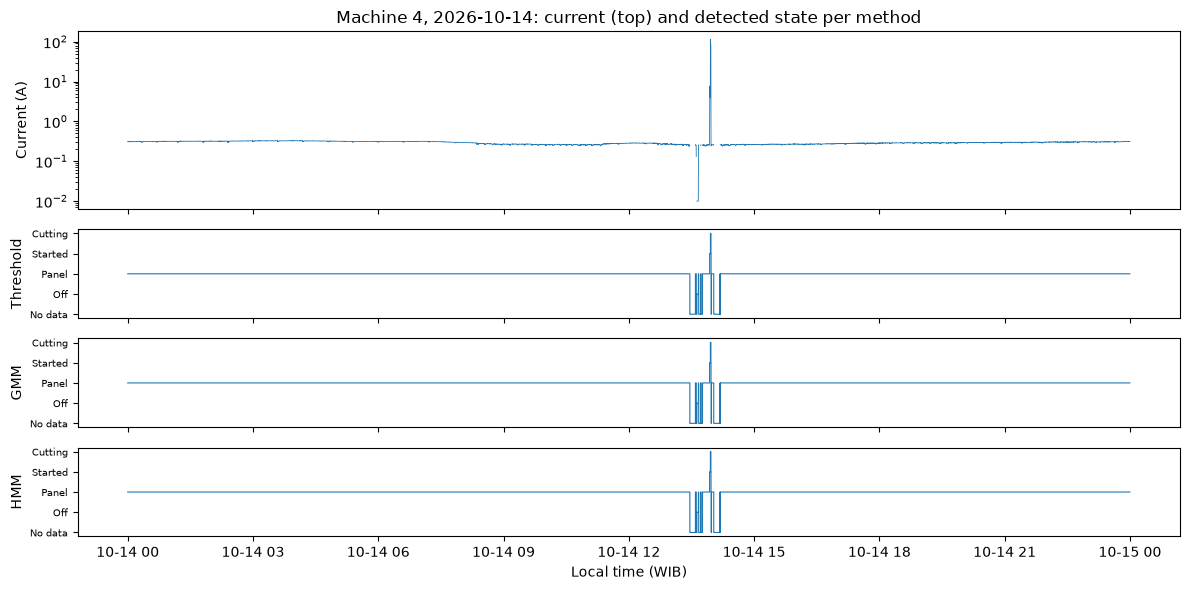

In [9]:
for day in SAMPLE_DAYS:
    m = (df.day == day).to_numpy()
    if not m.any(): print("no data for", day); continue
    fig, ax = plt.subplots(4, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1, 1]})
    ax[0].semilogy(df.t_local[m], df.I[m] + D.EPS, lw=.6); ax[0].set_ylabel("Current (A)")
    ax[0].set_title(f"Machine {MACHINE}, {day}: current (top) and detected state per method")
    for a, k in zip(ax[1:], ["A41 Threshold", "A42 GMM", "A43 HMM"]):
        a.step(df.t_local[m], S[k][m], where="post", lw=.8); a.set_ylabel(k.split()[1])
        a.set_yticks([-1, *D.CODES[K]], ["No data"] + [STATE[i] for i in D.CODES[K]], fontsize=7)
    ax[-1].set_xlabel("Local time (WIB)")
    fig.tight_layout(); fig.savefig(C.FIG / f"m{MACHINE}_visual_{day}.png"); plt.show()

## 9 · Save

In [10]:
out = df[["machine", "t"]].assign(**{f"k_{k.split()[1].lower()}": v for k, v in S.items()})
out.to_parquet(C.SILVER / f"states_m{MACHINE}.parquet", index=False)
v, d, i = D.runs(s)
ep = pd.DataFrame({"start": df.t.to_numpy()[i], "state": [STATE[int(k)] for k in v], "duration_s": d * 5})
ep.to_parquet(C.SILVER / f"episodes_m{MACHINE}.parquet", index=False)
print(f"states_m{MACHINE}.parquet ({len(out):,} slots), episodes_m{MACHINE}.parquet ({len(ep):,} episodes, {CHOSEN})")
print(f"H47: flickers/day GMM {ev.loc['A42 GMM','flickers_per_day']:.2f} vs HMM {ev.loc['A43 HMM','flickers_per_day']:.2f}; "
      f"switches/day GMM {ev.loc['A42 GMM','switches_per_day']:.1f} vs HMM {ev.loc['A43 HMM','switches_per_day']:.1f}")

states_m4.parquet (2,183,058 slots), episodes_m4.parquet (3,590 episodes, A43 HMM)
H47: flickers/day GMM 1.98 vs HMM 1.65; switches/day GMM 28.9 vs HMM 28.3
